# HDB Resale Analysis: A Market Split in Two?

**Problem statement:** why are HDB resale records being broken while overall prices are falling?

**Stakeholders:**
- **Homebuyers and sellers**, who need to know whether "the market" story applies to *their* flat, what a younger lease is worth, and whether a higher floor is worth paying for.
- **Policymakers (HDB, MND)**, who need to know which segments are pulling away and where lease decay starts to erode value.

This notebook uses the cleaned data from [`data-cleaning.ipynb`](data-cleaning.ipynb). Each section answers one question, first with simple grouped comparisons that are easy to explain, then with regression where it adds accuracy. The two approaches should agree.

| Section | Question |
|---|---|
| 1 | Data preparation: segments, lease bands and comparison periods |
| 2 | What happened to prices and million-dollar sales? |
| 3 | Is the headline dip real? (mix-adjusted index) |
| 4 | Has the market split, and when? |
| 5 | What drives price, before vs after the 2021 surge? |
| 6 | Do the headline stories hold up? (floor height, lease, S\$1M spread, the record sales) |
| 7 | Answer and recommendations |

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)

DATA_DIR = '../data'
RESALE_CLEAN_PATH = f'{DATA_DIR}/ResaleflatpricesbasedonregistrationdatefromJan2017onwards_clean.csv'
PROP_CLEAN_PATH = f'{DATA_DIR}/HDBPropertyInformation_clean.csv'

In [2]:
# Chart style: same as the cleaning notebook
INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, BLUE_LIGHT, ORANGE, AQUA = '#2a78d6', '#b7d3f6', '#eb6834', '#1baf7a'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'font.size': 9, 'figure.dpi': 110, 'figure.titlesize': 12, 'figure.titleweight': 'bold',
})
THOUSANDS = FuncFormatter(lambda x, _: f'{x:,.0f}')
PCT = FuncFormatter(lambda x, _: f'{x:+.0f}%')


def label_ends(ax, items, min_gap=0.05):
    """Label each line where it ends, in the line's colour, instead of using a legend.
    `items` is a list of (x, y, text, color). Labels that would overlap are pushed apart
    so they are at least `min_gap` (a share of the y-axis height) from each other."""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap
    items = sorted(items, key=lambda t: t[1])
    ys = [t[1] for t in items]
    for i in range(1, len(ys)):                      # push labels up until they are far enough apart
        ys[i] = max(ys[i], ys[i - 1] + gap)
    shift = max(0, ys[-1] - hi) if ys else 0         # if pushed past the top, move the whole stack down
    for (x, _, text, color), ly in zip(items, ys):
        ax.annotate(text, xy=(x, ly - shift), va='center', fontsize=8, color=color)


def date_axis(ax, short=False, every=1):
    """Readable date ticks: one per year for long periods, every 6 months for short ones."""
    if short:
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    else:
        ax.xaxis.set_major_locator(mdates.YearLocator(every))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

## 1. Data Preparation

Load the cleaned files:
- **Terrace flats (123 sales) are excluded.** They are landed-style units that would distort 3 ROOM and 4 ROOM comparisons.
- **The 2 sales with missing prices are excluded** from price analysis.
- **Quarters, not years, are the time unit**, because 2026 only covers Jan–Sep. Apr–May 2020 (COVID-19 circuit breaker) has very low volumes.
- Prices are **nominal** (not adjusted for inflation), as published.

In [3]:
resale = pd.read_csv(RESALE_CLEAN_PATH, dtype={'block': str, 'remaining_lease_months': 'Int64'})
prop = pd.read_csv(PROP_CLEAN_PATH, dtype={'blk_no': str})

# Block attributes used in the regression: height, shops, hawker centre, share of rental units
rental_cols = [c for c in prop.columns if c.endswith('_rental')]
prop['rental_share'] = prop[rental_cols].sum(axis=1) / prop['total_dwelling_units'].replace(0, np.nan)
BLOCK_COLS = ['max_floor_lvl', 'commercial', 'market_hawker', 'rental_share']

df = resale.merge(prop[['blk_no', 'street'] + BLOCK_COLS], left_on=['block', 'street_name'],
                  right_on=['blk_no', 'street'], how='left').drop(columns=['blk_no', 'street'])
print('All sales:', len(df))
df = df[~df['is_terrace'] & df['resale_price'].notna()].copy()
print('After excluding Terrace flats and missing prices:', len(df))

# Derived columns for the analysis
df['date'] = pd.to_datetime(df['month'])
df['year'] = df['date'].dt.year
df['quarter'] = df['date'].dt.to_period('Q')
df['price_per_sqm'] = df['resale_price'] / df['floor_area_sqm']
df['log_psm'] = np.log(df['price_per_sqm'])
df['lease_years'] = df['remaining_lease_months'].astype(float) / 12
df['lease_band'] = pd.cut(df['lease_years'], [0, 60, 70, 80, 90, 100], right=False,
                          labels=['<60', '60-70', '70-80', '80-90', '90+'])
df['storey_low'] = df['storey_range'].str[:2].astype(int)
df['storey_band'] = pd.cut(df['storey_low'], [0, 4, 10, 16, 25, 60], right=False,
                           labels=['01-03', '04-09', '10-15', '16-24', '25+'])
df['is_million'] = df['resale_price'] >= 1_000_000
df['lease_band'].value_counts().sort_index()

All sales: 241148
After excluding Terrace flats and missing prices: 241023


lease_band
<60      46060
60-70    57731
70-80    50317
80-90    32370
90+      54545
Name: count, dtype: int64

Identify "prime" towns as defined by the data. The news headlines showing record sales and million-dollar homes are concentrated in central areas so the problem statement assumes there are certain prime locations where buyers are willing to pay a lot more than others. 

So we define prime towns in a data-driven way:
1. Rank towns by median price per sqm in 2017-2019. This will be used as the baseline.
2. Compute the % drop in median price per sqm relative to the next town down on the list
3. Cut the list at the biggest drop. The towns above this point are prime towns. 

Looking at % drop instead of absolute values helps compare the gaps fairly across various price levels, since the same dollar gap means more between "cheaper" towns than "expensive" towns. 

In [4]:
# Identify the "prime" towns based on median price per sqm in 2017-2019, and the drop to the next town
base = df[df['year'].between(2017, 2019)]
town_rank = base.groupby('town')['price_per_sqm'].median().sort_values(ascending=False).to_frame('median_psm_2017_19')
town_rank['drop_to_next'] = town_rank['median_psm_2017_19'].pct_change().shift(-1)

top_half = town_rank.iloc[:len(town_rank) // 2]
cut = top_half['drop_to_next'].idxmin()          # the town just before the biggest drop
PRIME = list(town_rank.loc[:cut].index)
df['prime'] = df['town'].isin(PRIME)

print('Prime towns:', PRIME)
town_rank.head(10).style.format({'median_psm_2017_19': '{:,.0f}', 'drop_to_next': '{:.1%}'})

Prime towns: ['CENTRAL AREA', 'QUEENSTOWN', 'BUKIT TIMAH', 'BUKIT MERAH', 'MARINE PARADE', 'BISHAN']


,median_psm_2017_19,drop_to_next
town,,
CENTRAL AREA,"7,216",-9.4%
QUEENSTOWN,"6,538",-1.5%
BUKIT TIMAH,"6,442",-6.0%
BUKIT MERAH,"6,056",-1.9%
MARINE PARADE,"5,938",-1.4%
BISHAN,"5,856",-9.8%
KALLANG/WHAMPOA,"5,279",-5.3%
CLEMENTI,"5,000",-3.0%
TOA PAYOH,"4,850",-2.5%


- The biggest gap is after **Bishan**: the next town (Kallang/Whampoa) is 9.8% lower. So the **6 prime towns** are Central Area, Queenstown, Bukit Timah, Bukit Merah, Marine Parade and Bishan.
- These towns make up about 10% of sales each year, so they are a small but distinct segment.

**Comparison periods.** Section 5 and parts of Section 6 compare three periods:
- **2019:** the baseline. A normal, stable year before COVID-19 and before the surge.
- **2021:** the start of the surge (median price +14% on 2020, record sales volume).
- **2025–26:** now (Jan 2025 to Sep 2026), when prices levelled off.

In [5]:
# Categorize years into periods
df['period'] = np.select([df['year'] == 2019, df['year'] == 2021, df['year'] >= 2025], ['2019', '2021', '2025-26'], default='')
PERIODS = ['2019', '2021', '2025-26']
df[df['period'] != ''].groupby('period').agg(sales=('resale_price', 'size'), median_price=('resale_price', 'median'),
                                             median_psm=('price_per_sqm', 'median')).round(0)

,sales,median_price,median_psm
period,,,
2019,22172,400000.0,4175.0
2021,29068,483000.0,4915.0
2025-26,44149,630000.0,6488.0


---
## 2. What happened to prices and million-dollar sales?

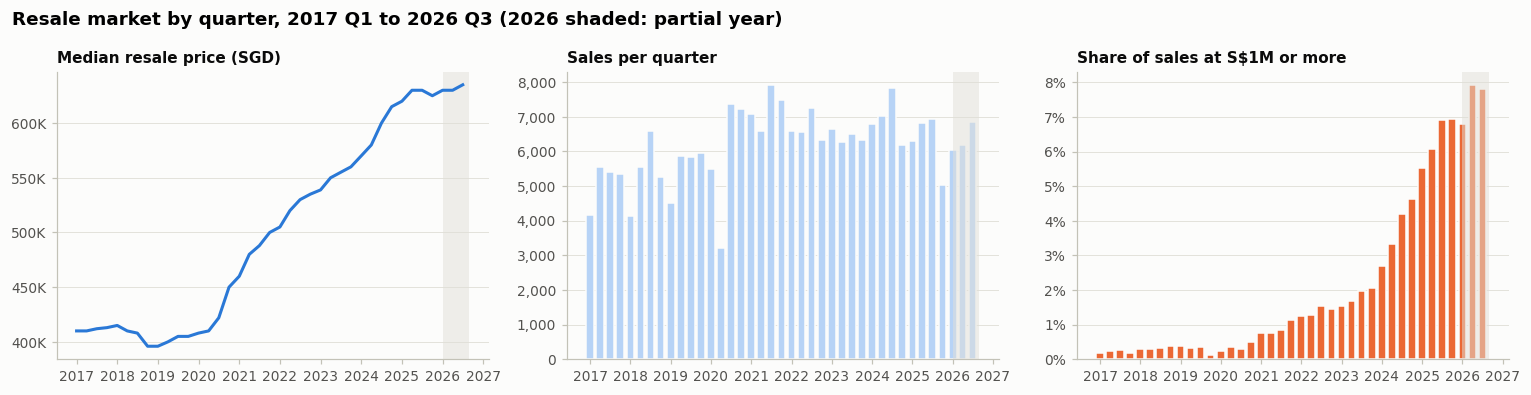

,sales,median_price,median_psm,million,million_share
quarter,,,,,
2024Q1,6787,570000.0,5882.4,182,2.7
2024Q2,7028,580000.0,6013.4,235,3.3
2024Q3,7829,600000.0,6176.5,329,4.2
2024Q4,6174,615000.0,6322.2,285,4.6
2025Q1,6302,620000.0,6422.9,348,5.5
2025Q2,6819,630000.0,6548.7,415,6.1
2025Q3,6937,630000.0,6524.1,479,6.9
2025Q4,5019,625000.0,6493.4,349,7.0
2026Q1,6040,630000.0,6498.1,411,6.8


In [6]:
# Analyze quarterly trends
# One row per quarter: number of sales, median price, median price per sqm, and how many sold for S$1M or more
qtr = df.groupby('quarter').agg(sales=('resale_price', 'size'), median_price=('resale_price', 'median'),
                                median_psm=('price_per_sqm', 'median'), million=('is_million', 'sum'))
qtr['million_share'] = qtr['million'] / qtr['sales'] * 100   # % of the quarter's sales at S$1M or more
x = qtr.index.to_timestamp()                                 # quarters (e.g. 2024Q1) -> dates, so matplotlib can place them on a time axis

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

# Panel 1: median resale price (in thousands) over time
axes[0].plot(x, qtr['median_price'], color=BLUE, linewidth=2)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1000:,.0f}K'))
axes[0].set_title('Median resale price (SGD)')

# Panel 2: volume of sales per quarter
axes[1].bar(x, qtr['sales'], width=70, color=BLUE_LIGHT, edgecolor=SURFACE)
axes[1].yaxis.set_major_formatter(THOUSANDS)                 # show 8,000 instead of 8000
axes[1].set_title('Sales per quarter')

# Panel 3: share of S$1M sales in %
axes[2].bar(x, qtr['million_share'], width=70, color=ORANGE, edgecolor=SURFACE)
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[2].set_title('Share of sales at S$1M or more')

# Shade 2026 in grey on every panel, to flag that it's a partial year (Jan-Sep)
for ax in axes:
    ax.axvspan(pd.Timestamp('2026-01-01'), x.max() + pd.Timedelta(days=60), color=GRID, alpha=0.5, linewidth=0)

# Overall title across all 3 panels, aligned left; tight_layout stops titles and labels overlapping
fig.suptitle('Resale market by quarter, 2017 Q1 to 2026 Q3 (2026 shaded: partial year)', x=0.01, ha='left')
fig.tight_layout()
plt.show()

# The table behind the charts, for the most recent quarters
qtr.loc['2024Q1':].round(1)

- The **median price rose from about S\$400K (2019) to S\$630K (2025)**, with most of the rise from 2021 to 2024. Since mid-2025 it has been **flat at about S\$625–635K**.
- **Sales at S\$1M or more kept rising** even after the median flattened: from 2.7% of sales in 2024 Q1 to **7.8% in 2026 Q3 (535 sales, a record)**.
- So while  the market looks flat, record sales keep coming. 

In [7]:
# By flat type: median price and S$1M share, 2019 vs 2025-26
by_type = (df[df['period'].isin(['2019', '2025-26'])]
           .groupby(['flat_type', 'period'])
           .agg(sales=('resale_price', 'size'), median_price=('resale_price', 'median'), million_share=('is_million', 'mean'))
           .unstack('period'))
by_type[('median_price', 'change')] = by_type[('median_price', '2025-26')] / by_type[('median_price', '2019')] - 1
fmt = {c: '{:,.0f}' if c[0] in ('sales', 'median_price') else '{:.1%}' for c in by_type.columns}
fmt[('median_price', 'change')] = '{:+.0%}'
by_type.loc[['2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE']].style.format(fmt)

- Every flat type's median price rose by roughly **50–65% between 2019 and 2025–26**.
- In 2025–26, **1 in 4 EXECUTIVE flats** and **1 in 10 5 ROOM flats** sold for S\$1M or more. Only 6.7% of 4 ROOM flats did, but because 4 ROOM is the most common type, they make up the **largest number** of S\$1M sales. 3 ROOM and smaller flats essentially never reach S\$1M.

## 3. Is the headline dip real?

News reports said HDB resale prices **fell for two quarters in 2026**, but the raw median in Section 2 kept edging up. The difference is that the HDB's Resale Price Index (RPI) **holds the mix of flats constant**; the median doesn't. If more expensive flats (larger, younger, central) are sold in one quarter, the median rises even if no flat is worth more.

So let's build a simple **mix-adjusted index** so we compare each type of flat with itself across time periods (so it only moves when similar flats change price).

1. Split sales into cells of **town × flat type × lease band** (similar flats).
2. In each quarter, take each cell's median price per sqm, relative to the same cell's median in 2017–2019.
3. Average these relative prices using **fixed weights** (each cell's share of sales in 2017–2019).

Because the weights never change, a shift in which flats get sold can't move the index. Only price changes for similar flats can.

In [8]:
def mix_index(data, cells=('town', 'flat_type', 'lease_band'), base_years=(2017, 2019), min_base_sales=10):
    """Mix-adjusted price index by quarter (2017-2019 = 100), in the spirit of HDB's RPI.
    Each cell of similar flats is compared with its own 2017-2019 median price per sqm, and cells are averaged
    with fixed 2017-2019 weights, so changes in which flats are sold don't move the index."""
    cells = list(cells)

    # Determine the baseline: for each cell of similar flats (e.g. Bedok / 4 ROOM / 60-70 years left),its median price per sqm and number of sales in 2017-2019
    base = data[data['year'].between(*base_years)].groupby(cells, observed=True)['price_per_sqm'].agg(['median', 'size'])
    base = base[base['size'] >= min_base_sales]           # skip cells too small (<10)for a stable baseline

    # Compute fixed weights: each cell's share of all 2017-2019 sales. These never change, so a cell that was 2% of the market in 2017-2019 counts as 2% in every quarter
    base['weight'] = base['size'] / base['size'].sum()

    # Get this quarter's price for each cell: median price per sqm, by quarter and cell
    q = data.groupby(['quarter'] + cells, observed=True)['price_per_sqm'].median().rename('q_median').reset_index()

    # Attach each cell's baseline median and weight to its quarterly median.
    # Cells without a baseline (too small in 2017-2019, or new, e.g. a young-lease band that didn't exist yet) drop out here
    q = q.merge(base[['median', 'weight']].reset_index(), on=cells)

    # Compare each cell with itself: 1.50 means similar flats now cost 50% more per sqm than in 2017-2019
    q['relative'] = q['q_median'] / q['median']

    # Get the weighted average of the cells' relative prices in each quarter, x 100 so 2017-2019 = 100.
    # Dividing by the weights actually present re-scales them to add up to 1 when some cells had no sales that quarter
    return q.groupby('quarter').apply(lambda g: (g['relative'] * g['weight']).sum() / g['weight'].sum() * 100)


idx = mix_index(df)   # like-for-like index for the whole market

# Raw (not mix-adjusted) versions, put on the same 2017-2019 = 100 scale so they can be compared with the index
raw = qtr['median_psm'] / df.loc[df['year'].between(2017, 2019), 'price_per_sqm'].median() * 100 # median price per sqm
raw_price = qtr['median_price'] / df.loc[df['year'].between(2017, 2019), 'resale_price'].median() * 100 # median price

# One table with all three measures, plus quarter-on-quarter % changes to compare the latest movements
compare = pd.DataFrame({'mix_adjusted_index': idx, 'raw_median_index': raw, 'raw_price_index': raw_price,
                        'median_price': qtr['median_price']})
compare['index_qoq'] = compare['mix_adjusted_index'].pct_change() * 100
compare['median_price_qoq'] = compare['median_price'].pct_change() * 100
compare.loc['2024Q4':].round(2)

,mix_adjusted_index,raw_median_index,raw_price_index,median_price,index_qoq,median_price_qoq
quarter,,,,,,
2024Q4,151.73,149.76,150.74,615000.0,3.02,2.50
2025Q1,153.51,152.14,151.96,620000.0,1.17,0.81
2025Q2,155.75,155.12,154.41,630000.0,1.46,1.61
2025Q3,156.30,154.54,154.41,630000.0,0.36,0.00
2025Q4,156.41,153.81,153.19,625000.0,0.07,-0.79
2026Q1,156.35,153.92,154.41,630000.0,-0.04,0.80
2026Q2,155.11,154.09,154.41,630000.0,-0.80,0.00
2026Q3,154.92,152.03,155.64,635000.0,-0.12,0.79


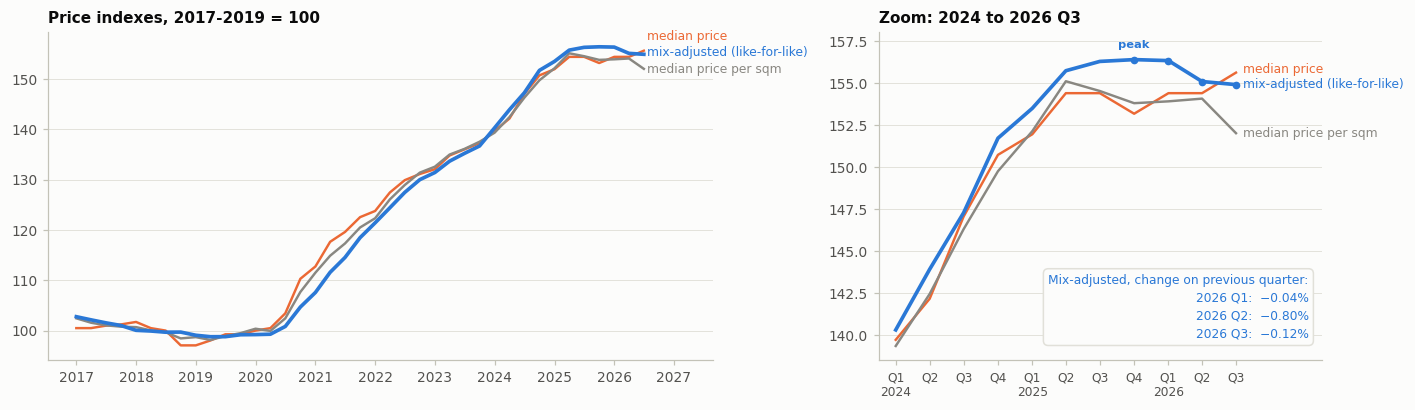

In [9]:
# Raw medians vs mix-adjusted index (all 2017-2019 = 100). Right panel zooms into 2024-2026.
LINES = [('raw_price_index', 'median price', ORANGE, 1.6), ('raw_median_index', 'median price per sqm', MUTED, 1.6),
         ('mix_adjusted_index', 'mix-adjusted (like-for-like)', BLUE, 2.4)]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 2]})
for ax, start in zip(axes, ['2017Q1', '2024Q1']):
    c = compare.loc[start:]
    xs = c.index.to_timestamp()
    for col, _, color, lw in LINES:
        ax.plot(xs, c[col], color=color, linewidth=lw)
    ax.set_xlim(right=xs[-1] + pd.Timedelta(days=420 if start == '2017Q1' else 230))
    label_ends(ax, [(xs[-1] + pd.Timedelta(days=20), c[col].iloc[-1], name, color) for col, name, color, _ in LINES])
    date_axis(ax, short=(start != '2017Q1'))
axes[0].set_title('Price indexes, 2017-2019 = 100')
axes[1].set_title('Zoom: 2024 to 2026 Q3')

# Zoom panel: label the x-axis by quarter (the year is shown under each Q1)
z = compare.loc['2024Q1':]
zx = z.index.to_timestamp()
axes[1].set_xticks(zx, [f'Q{q.quarter}' + (f'\n{q.year}' if q.quarter == 1 else '') for q in z.index], fontsize=8)

# Zoom panel: mark the peak and the three 2026 quarters on the mix-adjusted line with dots,
# then list each quarter's % change in a small key in the empty lower-right corner of the panel
marked = ['2025Q4', '2026Q1', '2026Q2', '2026Q3']
mx = [pd.Period(q).to_timestamp() for q in marked]
my = compare.loc[marked, 'mix_adjusted_index']
axes[1].plot(mx, my, 'o', color=BLUE, markersize=4)
axes[1].annotate('peak', xy=(mx[0], my.iloc[0]), xytext=(0, 8), textcoords='offset points',
                 ha='center', fontsize=7.5, color=BLUE, fontweight='bold')
axes[1].set_ylim(top=axes[1].get_ylim()[1] + 0.8)   # head-room so the 'peak' label fits inside the panel
key = 'Mix-adjusted, change on previous quarter:\n' + '\n'.join(
    f"{q[:4]} Q{q[-1]}:  {compare.loc[q, 'index_qoq']:+.2f}%".replace('-', '−') for q in marked[1:])
axes[1].text(0.97, 0.06, key, transform=axes[1].transAxes, ha='right', va='bottom', fontsize=8, color=BLUE,
             linespacing=1.5, bbox=dict(facecolor=SURFACE, edgecolor=GRID, boxstyle='round,pad=0.4'))
fig.tight_layout()
plt.show()

- The mix-adjusted index **peaked in 2025 Q4 and fell in every 2026 quarter: Q1 (−0.04%), Q2 (−0.8%) and Q3 (−0.1%)**, about 1% in total. So this means that the reported dip is **real**: similar flats sold for slightly less. Q1 and Q2 both being down matches the news of a "second straight quarter" of decline in Q2.
- The raw measures **don't show the dip clearly**, because they move with the **mix** of flats sold:
  - The **median price** didn't fall in any 2026 quarter (flat in Q2, +0.8% in Q3), because more large flats were sold.
  - The **median price per sqm** was flat in Q2, when like-for-like prices fell most, then fell 1.3% in Q3, when they barely moved.
- Over the whole period, the mix-adjusted index rose about **55%** from 2017–2019, so prices are falling from a very high level.

**First answer to the problem statement:** both headlines are true. Comparing the same kind of flat (ie. same town, same flat type, and same lease band) prices dipped slightly, while the mix of flats being sold (there are more sales for bigger flats), and the record sales, kept the raw numbers high.

## 4. Has the market split, and when?

The problem statement suggests a **premium segment** (young lease, prime estates, large flats) that keeps rising, and a **mainstream segment** that is softening.

So let's investigate this by:
- Running the same mix-adjusted index **separately for each segment**: prime vs other towns, each lease band, and each flat type.
- Compare the full period (2017-2019 = 100) then zoom into 2024-2026 to see where the recent dip comes from.

Another approach is also to:
- Compare prime and other towns **within the same lease band**, so that the result isn't driven by prime towns having older flats.

In [10]:
segments = {
    'Location': {'Prime towns': df['prime'], 'Other towns': ~df['prime']},
    'Lease left': {f'{b} years': df['lease_band'] == b for b in ['<60', '60-70', '70-80', '80-90', '90+']},
    'Flat type': {ft: df['flat_type'] == ft for ft in ['3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE']},
}
seg_idx = {grp: {name: mix_index(df[mask]) for name, mask in d.items()} for grp, d in segments.items()}

# Change in each segment: full period, and since prices peaked
rows = []
for grp, d in seg_idx.items():
    for name, s in d.items():
        rows.append({'group': grp, 'segment': name,
                     '2017-19 to 2026Q3': s['2026Q3'] / 100 - 1,
                     '2019 to 2021 (surge start)': s['2021Q4'] / s['2019Q4'] - 1,
                     '2025Q2 to 2026Q3 (recent)': s['2026Q3'] / s['2025Q2'] - 1})
seg_change = pd.DataFrame(rows).set_index(['group', 'segment'])
seg_change.style.format('{:+.1%}')

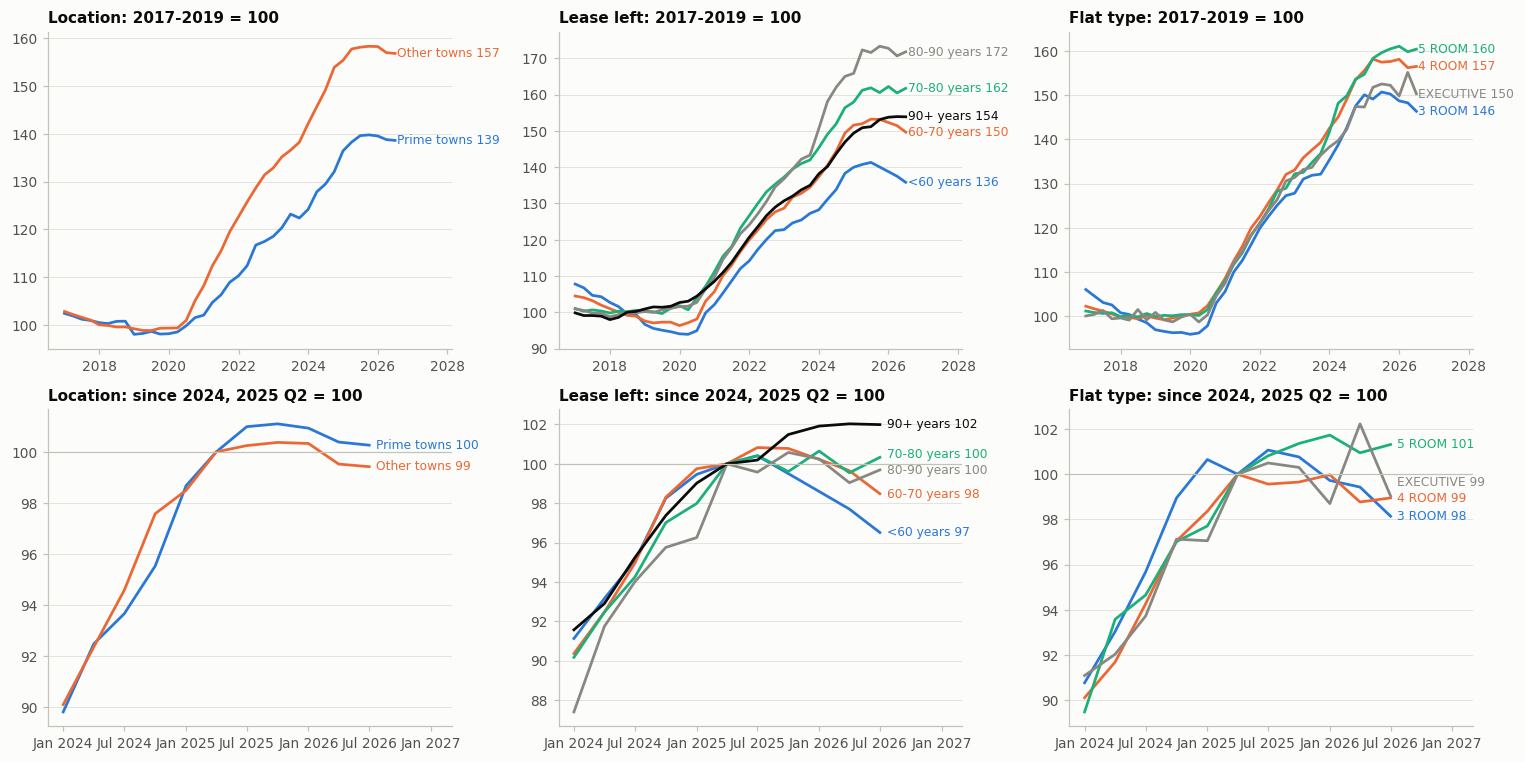

In [11]:
# One panel per grouping. Top row: full period (2017-2019 = 100). Bottom row: since 2024, rebased to 2025 Q2 = 100.
COLORS = [BLUE, ORANGE, AQUA, MUTED, INK]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, (grp, d) in enumerate(seg_idx.items()):
    ends = {0: [], 1: []}
    for (name, s), color in zip(d.items(), COLORS):
        for row, (start, rebase) in enumerate([('2017Q1', None), ('2024Q1', '2025Q2')]):
            ax = axes[row, col]
            v = s.loc[start:]
            v = v / s[rebase] * 100 if rebase else v
            xs = v.index.to_timestamp()
            ax.plot(xs, v, color=color, linewidth=1.8)
            ends[row].append((xs[-1] + pd.Timedelta(days=20), v.iloc[-1], f'{name} {v.iloc[-1]:.0f}', color))
    axes[0, col].set_title(f'{grp}: 2017-2019 = 100')
    axes[1, col].set_title(f'{grp}: since 2024, 2025 Q2 = 100')
    axes[1, col].axhline(100, color=AXIS, linewidth=0.8)
    for row in (0, 1):
        ax = axes[row, col]
        ax.set_xlim(right=ax.get_xlim()[1] + (420 if row == 0 else 200))
        label_ends(ax, ends[row])
        date_axis(ax, short=(row == 1), every=2)
fig.tight_layout()
plt.show()

**Location: prime towns have *not* pulled away.**
- Since 2017–2019, like-for-like prices rose **about 39% in prime towns vs about 57% in other towns**. Outer towns caught up, most of all at the start of the surge (2019 to 2021: +11% prime vs +20% other).
- Since 2025 Q2, both have been roughly flat (prime +0.3%, other −0.6%).

**Lease: the clearest split.**
- Over the full period, flats with **80–90 years left rose the most (about 72%)** and flats with **under 60 years rose the least (about 36%)**.
- Since 2025 Q2, flats with **90+ years left are still rising (+2%)**, while flats with **under 60 years fell about 3.5%** and 60–70 years fell about 1.5%.

**Flat type: a smaller split.** Since 2025 Q2, **5 ROOM** flats are still edging up while **3 ROOM** flats fell about 2%.

So the market **has** started to split since mid-2025, but along **lease and size**, not location.

In [12]:
# Like-for-like: prime vs other towns within the same lease band (cells: town x flat type)
ll = {}
for band in ['<60', '60-70', '80-90', '90+']:
    for is_prime, label in [(True, 'Prime'), (False, 'Other')]:
        s = mix_index(df[(df['lease_band'] == band) & (df['prime'] == is_prime)], cells=('town', 'flat_type'), min_base_sales=5)
        ll[(band, label)] = {'2019Q4': s['2019Q4'], '2025Q2': s['2025Q2'], '2026Q3': s['2026Q3'],
                             'recent change': s['2026Q3'] / s['2025Q2'] - 1}
pd.DataFrame(ll).T.style.format({'2019Q4': '{:.0f}', '2025Q2': '{:.0f}', '2026Q3': '{:.0f}', 'recent change': '{:+.1%}'})

- The lease split holds **in both prime and other towns**: since 2025 Q2, flats with 90+ years left went up in both, and flats with under 60 years went down in both. It isn't a location effect in disguise.
- The fall in old-lease flats is **steeper in prime towns** (about −4%) than elsewhere (about −3%). Prime towns have more old flats, which is part of why their overall index lags.

**When did it start?** During the 2021–2024 surge, every lease band and flat type rose, and other towns rose faster than prime towns. The split by lease and size appears from **2025 Q2**, when overall prices stopped rising: younger and larger flats kept going up, older and smaller ones turned down.

## 5. What drives price, before vs after the 2021 surge?

1. Compare the price per sqm of prime vs other towns **for the same flat type and lease band**, year by year. This shows whether the location premium has grown or shrunk.

2. In each period (2019, 2021, 2025–26), fit:

`log(price per sqm) ~ town + flat type + lease band + storey band + block height + shops in block + hawker centre in block + share of rental units`

Each coefficient becomes a **% premium** compared with a reference flat: a 4 ROOM in Ang Mo Kio with 60–70 years left, on floors 4–9. Then each group of factors is removed in turn to see **how much of the price differences it explains** (the drop in R²).

In [13]:
def like_for_like_gap(data, group_col, hi, lo, cells=('flat_type', 'lease_band'), min_n=10):
    """Average % gap in median price per sqm between two groups (`hi` vs `lo` in `group_col`), comparing like with like.
    The gap is measured within each cell of similar flats, then averaged, weighting each cell by the smaller group's sales."""
    t = data.groupby(list(cells) + [group_col], observed=True)['price_per_sqm'].agg(['median', 'size']).unstack(group_col)
    t = t.dropna()
    t = t[(t[('size', hi)] >= min_n) & (t[('size', lo)] >= min_n)]
    w = np.minimum(t[('size', hi)], t[('size', lo)])
    return ((t[('median', hi)] / t[('median', lo)] - 1) * w).sum() / w.sum()


prime_gap = pd.Series({y: like_for_like_gap(df[df['year'] == y], 'prime', True, False) for y in range(2017, 2027)})
prime_gap.map('{:+.1%}'.format).rename('prime vs other towns, same flat type and lease band')

2017    +47.2%
2018    +51.2%
2019    +50.8%
2020    +48.9%
2021    +42.5%
2022    +36.2%
2023    +35.7%
2024    +31.5%
2025    +33.5%
2026    +37.2%
Name: prime vs other towns, same flat type and lease band, dtype: str

- For the same flat type and lease band, prime towns cost **about 47–51% more per sqm in 2017–2019**. That premium **narrowed to about 32–37% in 2024–2026**.
- So the location premium has actually **shrunk**, not grown. This is the same result as the segment index in Section 4.

In [14]:
REF = {'town': 'ANG MO KIO', 'flat_type': '4 ROOM', 'lease_band': '60-70', 'storey_band': '04-09'}
FORMULA = ('log_psm ~ ' + ' + '.join(f"C({k}, Treatment('{v}'))" for k, v in REF.items())
           + ' + max_floor_lvl + commercial + market_hawker + rental_share')

reg_data = df[(df['period'] != '') & df['max_floor_lvl'].notna()]
models = {p: smf.ols(FORMULA, data=reg_data[reg_data['period'] == p]).fit(cov_type='HC1') for p in PERIODS}
pd.DataFrame({p: {'sales': int(m.nobs), 'R²': round(m.rsquared, 3)} for p, m in models.items()})

,2019,2021,2025-26
sales,22172.000,29068.000,44149.000
R²,0.768,0.762,0.792


In [15]:
def premiums(model, scale=None):
    """Turn regression coefficients into readable % premiums vs the reference flat, marking p < 0.05 with '*'.
    Continuous factors are scaled to a sensible step (e.g. per 10 floors) using `scale`."""
    scale = scale or {}
    out = {}
    for name, coef in model.params.items():
        if name == 'Intercept':
            continue
        label = name.split('[T.')[1].rstrip(']') if '[T.' in name else name
        factor = name.split('(')[1].split(',')[0] if name.startswith('C(') else name.split('[')[0]
        step = scale.get(factor, 1)
        out[(factor, label)] = (np.exp(coef * step) - 1) * 100, model.pvalues[name] < 0.05
    return out


SCALE = {'max_floor_lvl': 10, 'rental_share': 0.1}   # per 10 floors, per 10 percentage points of rental units
prem = {p: premiums(m, SCALE) for p, m in models.items()}
table = pd.DataFrame({p: {k: f'{v:+.1f}%' + ('*' if sig else '') for k, (v, sig) in d.items()} for p, d in prem.items()})
table.loc[[k for k in table.index if k[0] != 'town']]

2019     2021  2025-26
flat_type     1 ROOM            +15.9%*  +24.2%*  +29.1%*
              2 ROOM             +3.7%*   +5.9%*  +10.7%*
              3 ROOM             +1.3%*   +3.7%*   +3.8%*
              5 ROOM              +0.1%    -0.2%   -2.5%*
              EXECUTIVE          +9.0%*   +6.7%*   +5.9%*
              MULTI-GENERATION  +20.1%*  +11.3%*  +15.8%*
lease_band    <60               -11.5%*  -13.4%*   -9.3%*
              70-80              +3.9%*   +3.8%*   +5.4%*
              80-90             +13.7%*  +14.6%*  +24.0%*
              90+               +30.9%*  +28.4%*  +27.2%*
storey_band   01-03              -4.9%*   -4.6%*   -4.0%*
              10-15              +4.3%*   +3.6%*   +2.8%*
              16-24              +8.3%*   +6.7%*   +7.1%*
              25+               +14.6%*  +13.0%*  +14.6%*
commercial    True               -0.6%*   -0.9%*   -0.6%*
market_hawker True               -0.0%*  -12.6%*   -8.7%*
max_floor_lvl max_floor_lvl      +5.7%*   +5.4%*   +5.6%*
rental_share  rental_share       +0.9%*   +1.3%*   +0.3%*

(`*` = statistically significant at p < 0.05. Block height is per 10 floors; rental share is per 10 percentage points of rental units in the block.)

- **Lease:** compared with 60–70 years left, flats with **80–90 years left carry a premium that grew from about +14% (2019) to +24% (2025–26)**. Flats with 90+ years carry about +27–31% in every period, and flats under 60 years about −9% to −13%.
- **Storey:** the premium for higher floors is **stable**: about +15% for floors 25+ vs floors 4–9 in both 2019 and 2025–26.
- **Flat type:** once size is measured per sqm, flat type matters little. Smaller flats cost slightly *more* per sqm.
- **Block features:** each extra **10 floors of block height adds about 5–6%**, likely because tall blocks are newer and more sought after. A hawker centre in the block is linked to about −9% to −13% in 2021 and 2025–26. Shops in the block and the share of rental units make less than 1.5% difference.

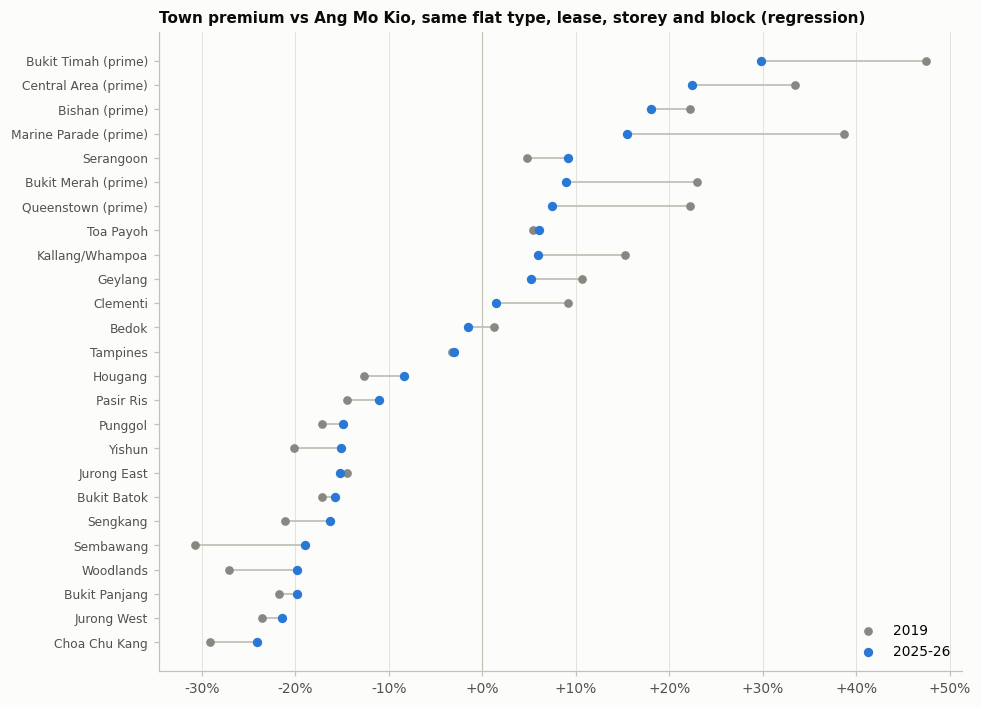

In [16]:
# Town premiums vs Ang Mo Kio, 2019 vs 2025-26: each line joins the two periods for one town
towns = pd.DataFrame({p: {k[1]: v for k, (v, _) in prem[p].items() if k[0] == 'town'} for p in PERIODS})
towns = towns.sort_values('2025-26')

fig, ax = plt.subplots(figsize=(9, 6.5))
y = range(len(towns))
ax.hlines(y, towns['2019'], towns['2025-26'], color=AXIS, linewidth=1.2)
ax.scatter(towns['2019'], y, color=MUTED, s=22, label='2019', zorder=3)
ax.scatter(towns['2025-26'], y, color=BLUE, s=26, label='2025-26', zorder=3)
ax.set_yticks(list(y), [t.title() + (' (prime)' if t in PRIME else '') for t in towns.index], fontsize=8)
ax.axvline(0, color=AXIS, linewidth=0.8)
ax.xaxis.set_major_formatter(PCT)
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Town premium vs Ang Mo Kio, same flat type, lease, storey and block (regression)')
fig.tight_layout()
plt.show()

- Using Ang Mo Kio as a reference town (being middle of price range, with plenty of sales, and a typical mature and non-prime HDB town) :
  - **Town premiums have converged.** Prime towns' premiums **shrank**: Bukit Timah from +48% to +30%, Marine Parade from +39% to +16%, Queenstown from +22% to +7%, Bukit Merah from +23% to +9%.
  - Outer towns' **discounts narrowed**: Sembawang from −31% to −19%, Woodlands from −27% to −20%.
  - The regression agrees with the simple comparison above: **location matters less than it did before the surge**.

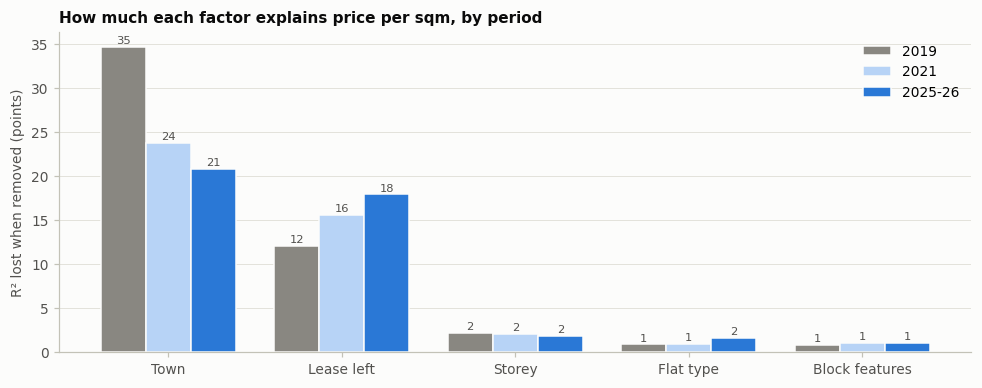

,2019,2021,2025-26
Town,34.6,23.8,20.8
Lease left,12.1,15.6,17.9
Storey,2.2,2.1,1.8
Flat type,0.9,0.9,1.6
Block features,0.9,1.0,1.1


In [17]:
# How much of the variation in price per sqm each group of factors explains: drop in R² when that group is removed
GROUPS = {
    'Town': f"C(town, Treatment('{REF['town']}'))",
    'Lease left': f"C(lease_band, Treatment('{REF['lease_band']}'))",
    'Storey': f"C(storey_band, Treatment('{REF['storey_band']}'))",
    'Flat type': f"C(flat_type, Treatment('{REF['flat_type']}'))",
    'Block features': 'max_floor_lvl + commercial + market_hawker + rental_share',
}
contrib = {}
for p in PERIODS:
    d = reg_data[reg_data['period'] == p]
    full = models[p].rsquared
    contrib[p] = {g: (full - smf.ols('log_psm ~ ' + ' + '.join(t for k, t in GROUPS.items() if k != g), data=d).fit().rsquared) * 100
                  for g in GROUPS}
contrib = pd.DataFrame(contrib)

fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.26
for i, (p, color) in enumerate(zip(PERIODS, [MUTED, BLUE_LIGHT, BLUE])):
    xs = np.arange(len(contrib)) + (i - 1) * w
    ax.bar(xs, contrib[p], width=w, color=color, label=p, edgecolor=SURFACE)
    for xi, v in zip(xs, contrib[p]):
        ax.annotate(f'{v:.0f}', xy=(xi, v), xytext=(0, 2), textcoords='offset points', ha='center', fontsize=7.5, color=INK_2)
ax.set_xticks(range(len(contrib)), contrib.index)
ax.set_ylabel('R² lost when removed (points)')
ax.legend(frameon=False)
ax.set_title('How much each factor explains price per sqm, by period')
fig.tight_layout()
plt.show()
contrib.round(1)

- The model explains about **76–79% of the variation** in price per sqm in each period.
- **Town is still the biggest factor, but it has shrunk**: it explains about 35 points of R² in 2019, 24 in 2021 and 21 in 2025–26.
- **Lease left has grown**: from about 12 points (2019) to 16 (2021) and 18 (2025–26). It is now almost as important as location.
- Storey, flat type and block features each explain only 1–2 points.

**For a homebuyer or seller:** *how long the lease has left* now matters almost as much as *which town* the flat is in. Paying a large premium just for a "prime" address buys less than it did in 2019.

## 6. Do the headline stories hold up?

### 6.1 Is floor height losing importance?

The two record sales in the news (Pinnacle@Duxton and Sengkang 279B) were both on **lower floors** than earlier record holders. Does that mean buyers care less about height?

Compare each sale with other sales of the **same flat type in the same block and period**. Within one block, location, age and lease are the same, so the difference is mostly the floor. Only groups with at least 5 sales are used.

**Cross-check with the regression:** the Section 5 regression already estimates a premium for each storey band, holding town, flat type, lease and block features constant. Those estimates are shown next to the within-block results, without fitting a new model, to see whether the two agree.

In [18]:
grp_keys = ['block', 'street_name', 'flat_type', 'period']
wb = df[df['period'] != ''].copy()
wb['grp_mean'] = wb.groupby(grp_keys)['log_psm'].transform('mean')
wb['grp_n'] = wb.groupby(grp_keys)['log_psm'].transform('size')
wb = wb[wb['grp_n'] >= 5]
wb['dev'] = wb['log_psm'] - wb['grp_mean']

storey = wb.groupby(['storey_band', 'period'], observed=True)['dev'].mean().unstack('period')
storey_within = (np.exp(storey.sub(storey.loc['04-09'])) - 1) * 100
storey_reg = pd.DataFrame({p: {b: prem[p].get(('storey_band', b), (0, False))[0] for b in storey_within.index} for p in PERIODS})

pd.concat({'Within same block (simple)': storey_within, 'Regression': storey_reg}, axis=1).round(1)

Within same block (simple)              Regression              
period                       2019 2021 2025-26       2019  2021 2025-26
01-03                        -4.9 -4.6    -4.0       -4.9  -4.6    -4.0
04-09                         0.0  0.0     0.0        0.0   0.0     0.0
10-15                         2.9  3.0     2.5        4.3   3.6     2.8
16-24                         4.2  4.3     3.6        8.3   6.7     7.1
25+                           5.3  5.6     5.5       14.6  13.0    14.6

- **Within the same block, the floor premium is small and stable:** floors 25+ sell for about **+5–6%** more per sqm than floors 4–9, in 2019, 2021 and 2025–26. Floors 1–3 sell for about 4–5% less.
- The regression gives a larger premium for floors 25+ (about +15%) because it compares *across* blocks, where high floors also mean taller, newer, better-located blocks. The within-block comparison is the fairer measure of height alone.
- In both approaches, the premium **did not shrink** between 2019 and 2025–26.

**So floor height is not losing importance; it was never worth as much as people assume.** A ~5% premium is easily outweighed by differences in lease, layout, view and condition between units. That's why a lower-floor unit can set a record (see 6.4).

### 6.2 How much is lease worth?

Within each **town × flat type**, compare the median price per sqm of flats with more lease left against flats with 60–70 years left, then average across towns and flat types.

**Cross-check with the regression:** the Section 5 regression already estimates a premium for each lease band, holding town, flat type, storey and block features constant. Those estimates are shown below the simple comparison, without fitting a new model, to see whether the two agree.

In [19]:
lease_gap = pd.DataFrame({
    y: {'90+ vs 60-70 years': like_for_like_gap(df[df['year'] == y], 'lease_band', '90+', '60-70', cells=('town', 'flat_type')),
        '80-90 vs 60-70 years': like_for_like_gap(df[df['year'] == y], 'lease_band', '80-90', '60-70', cells=('town', 'flat_type')),
        '60-70 vs <60 years': like_for_like_gap(df[df['year'] == y], 'lease_band', '60-70', '<60', cells=('town', 'flat_type'))}
    for y in range(2017, 2027)}).T * 100
lease_reg = pd.DataFrame({p: {b: prem[p][('lease_band', b)][0] for b in ['<60', '70-80', '80-90', '90+']} for p in PERIODS})
display(lease_gap.round(1))
lease_reg.round(1).rename_axis('regression: vs 60-70 years')

,90+ vs 60-70 years,80-90 vs 60-70 years,60-70 vs <60 years
2017,39.7,24.5,1.8
2018,40.8,27.3,2.0
2019,39.5,38.4,4.5
2020,43.1,34.5,6.6
2021,36.1,37.2,7.2
2022,36.7,36.4,5.3
2023,30.2,34.0,5.5
2024,28.3,32.9,3.4
2025,26.5,28.2,3.0
2026,31.6,29.0,4.8


,2019,2021,2025-26
regression: vs 60-70 years,,,
<60,-11.5,-13.4,-9.3
70-80,3.9,3.8,5.4
80-90,13.7,14.6,24.0
90+,30.9,28.4,27.2


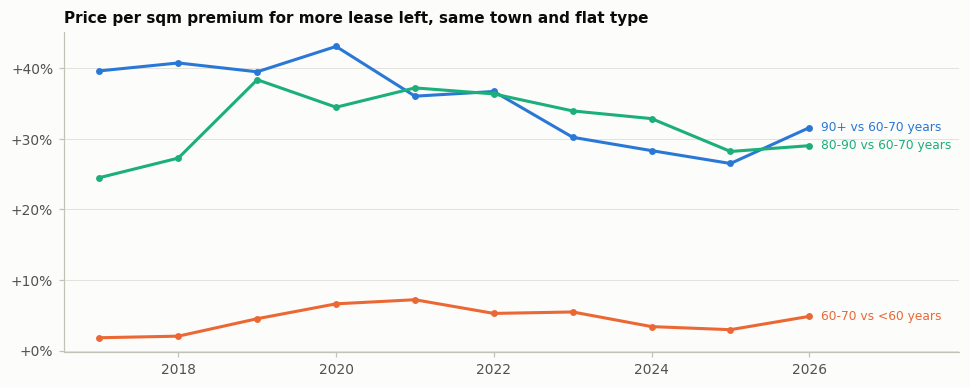

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for col, color in zip(lease_gap.columns, [BLUE, AQUA, ORANGE]):
    ax.plot(lease_gap.index, lease_gap[col], color=color, linewidth=2, marker='o', markersize=3.5)
ax.set_xlim(right=2027.9)
label_ends(ax, [(2026.15, lease_gap[c].iloc[-1], c, color) for c, color in zip(lease_gap.columns, [BLUE, AQUA, ORANGE])])
ax.yaxis.set_major_formatter(PCT)
ax.set_title('Price per sqm premium for more lease left, same town and flat type')
fig.tight_layout()
plt.show()

- A flat with **90+ years left costs about 26–43% more per sqm** than a similar flat in the same town with 60–70 years left. Even the step from under 60 years to 60–70 years is worth about 2–7%.
- The **simple comparison** shows the 90+ premium **narrowed** from about 40% (2019) to 27–32% (2025–26). The **regression** shows it roughly stable at 27–31%, while the **80–90 year premium grew** from +14% to +24%.
- Both agree that a long lease commands a large premium today. They differ on the trend partly because the simple comparison only uses town × flat type cells with enough sales in *both* lease bands, and there are fewer of those in recent years. The regression uses every sale.

**For a homebuyer:** a flat with 60–70 years left is roughly **a fifth to a quarter cheaper per sqm** than a young flat in the same town, but it has also been a falling segment since mid-2025 (Section 4). The discount reflects real risk to resale value, not a bargain.

### 6.3 Is the S\$1M surge a premium boom, or just the whole market crossing a fixed line?

S\$1M is a **nominal** line. If all prices rise by 55%, a flat that was worth S\$650K in 2019 is now worth about S\$1M without anything special happening.

**Approach:** compare two counts:
- **Nominal:** sales at S\$1M or more.
- **Market-adjusted:** sales above a line that moves with the mix-adjusted index from Section 3, set to S\$1M in 2026 Q3 (so about S\$640K in 2019). If the top end were pulling away from the market, the share above *this* line would rise too.

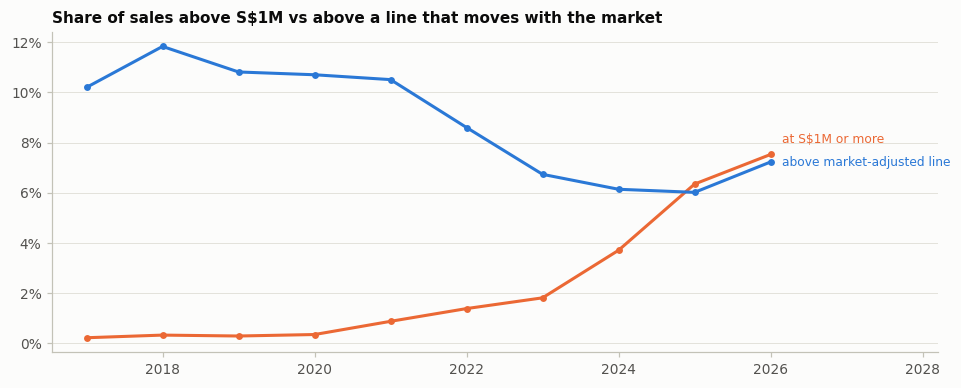

,sales,nominal,adjusted,line,nominal_share,adjusted_share
year,,,,,,
2017,20497,45,2090,657000.0,0.22,10.20
2018,21549,70,2549,644000.0,0.32,11.83
2019,22172,64,2397,639000.0,0.29,10.81
2020,23318,81,2495,655000.0,0.35,10.70
2021,29068,254,3054,731000.0,0.87,10.51
2022,26707,369,2296,812000.0,1.38,8.60
2023,25745,466,1733,866000.0,1.81,6.73
2024,27818,1031,1707,941000.0,3.71,6.14
2025,25077,1591,1508,1004000.0,6.34,6.01


In [21]:
df['million_line'] = 1_000_000 * df['quarter'].map(idx) / idx['2026Q3']
df['above_adj_line'] = df['resale_price'] >= df['million_line']

yearly = df.groupby('year').agg(sales=('resale_price', 'size'), nominal=('is_million', 'sum'), adjusted=('above_adj_line', 'sum'),
                                line=('million_line', 'mean'))
yearly['nominal_share'] = yearly['nominal'] / yearly['sales'] * 100
yearly['adjusted_share'] = yearly['adjusted'] / yearly['sales'] * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(yearly.index, yearly['nominal_share'], color=ORANGE, linewidth=2, marker='o', markersize=3.5)
ax.plot(yearly.index, yearly['adjusted_share'], color=BLUE, linewidth=2, marker='o', markersize=3.5)
ax.set_xlim(right=2028.2)
label_ends(ax, [(2026.15, yearly['nominal_share'].iloc[-1], 'at S$1M or more', ORANGE),
                (2026.15, yearly['adjusted_share'].iloc[-1], 'above market-adjusted line', BLUE)], min_gap=0.07)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.set_title('Share of sales above S$1M vs above a line that moves with the market')
fig.tight_layout()
plt.show()
yearly.round({'line': -3, 'nominal_share': 2, 'adjusted_share': 2})

- At a fixed S\$1M, the share of sales jumped from **0.3% (2019) to 7.5% (2026)**, about 25 times.
- Against the market-adjusted line, the share was **about 10–12% in 2017–2021**, fell to **about 6–7% in 2023–2025** (the mainstream caught up during the surge), and has **only recently recovered to about 7%** in 2026.
- So **most of the million-dollar surge is the whole market rising past a fixed line**, not a premium segment pulling away. The top end has only started to pull away again in 2026, in line with the lease and size split from Section 4.

In [22]:
# Where S$1M sales happen: towns with at least one S$1M sale, and the first year each town reached S$1M
mil = df[df['is_million']]
first_year = mil.groupby('town')['year'].min().sort_values()
by_town = mil.pivot_table(index='town', columns='year', values='resale_price', aggfunc='size', fill_value=0)
print('Towns with at least one S$1M sale, by year:', (by_town > 0).sum().to_dict())
print()
print('First year each town had a S$1M sale:')
print(first_year.groupby(first_year).apply(lambda s: ', '.join(t.title() for t in s.index)).to_string())
by_town.loc[by_town[2026].sort_values(ascending=False).index[:12], [2021, 2023, 2025, 2026]]

Towns with at least one S$1M sale, by year: {2017: 8, 2018: 9, 2019: 8, 2020: 9, 2021: 10, 2022: 21, 2023: 22, 2024: 23, 2025: 23, 2026: 23}

First year each town had a S$1M sale:
year
2017    Bishan, Central Area, Bukit Timah, Clementi, K...
2018                                 Bukit Merah, Hougang
2020                                  Geylang, Ang Mo Kio
2022    Pasir Ris, Jurong East, Bedok, Bukit Batok, Yi...
2023                                        Bukit Panjang
2024                                             Sengkang


year,2021,2023,2025,2026
town,,,,
TOA PAYOH,31,56,302,227
QUEENSTOWN,38,48,173,198
BUKIT MERAH,24,62,216,172
ANG MO KIO,5,31,80,107
KALLANG/WHAMPOA,14,51,145,105
CLEMENTI,10,31,106,75
TAMPINES,0,2,68,74
BEDOK,0,9,39,73
BISHAN,37,45,98,70


- S\$1M sales have spread **from a handful of central towns to 23 of the 26 towns**. The big jump was in **2022**, when the number of towns with a S\$1M sale doubled from 10 to 21. Sengkang was the latest to join, in 2024.
- The 2026 leaders are **Toa Payoh, Queenstown and Bukit Merah**, but mature non-prime towns (Kallang/Whampoa, Ang Mo Kio, Clementi, Tampines, Bedok) each have dozens of S\$1M sales a year.

### 6.4 The two record sales in the news

In [23]:
# Pinnacle@Duxton (Cantonment Rd blocks 1A-1G): 5 ROOM sales since 2025 at S$1.55M or more, in date order
pinnacle = df[(df['street_name'] == 'CANTONMENT RD') & df['block'].isin(['1A', '1B', '1C', '1D', '1E', '1F', '1G'])
              & (df['flat_type'] == '5 ROOM')]
display(pinnacle[(pinnacle['year'] >= 2025) & (pinnacle['resale_price'] >= 1_550_000)]
        .sort_values('date')[['month', 'block', 'storey_range', 'floor_area_sqm', 'lease_years', 'resale_price', 'price_per_sqm']].round(0))

# Sengkang: the 5 ROOM sales at S$1.06M or more
sk = df[(df['town'] == 'SENGKANG') & (df['flat_type'] == '5 ROOM')]
sk.nlargest(6, 'resale_price')[['month', 'block', 'street_name', 'storey_range', 'floor_area_sqm', 'lease_years', 'resale_price']].round(1)

,month,block,storey_range,floor_area_sqm,lease_years,resale_price,price_per_sqm
199799,2025-02,1D,43 TO 45,106.0,85.0,1550000.0,14623.0
206098,2025-05,1G,37 TO 39,107.0,85.0,1568380.0,14658.0
208386,2025-06,1D,34 TO 36,105.0,85.0,1580000.0,15048.0
210662,2025-07,1G,43 TO 45,105.0,85.0,1580000.0,15048.0
213201,2025-08,1G,49 TO 51,105.0,84.0,1600000.0,15238.0
215365,2025-09,1A,40 TO 42,107.0,84.0,1590000.0,14860.0
217361,2025-10,1B,28 TO 30,105.0,84.0,1550000.0,14762.0
222569,2026-01,1A,19 TO 21,106.0,84.0,1560000.0,14717.0
230570,2026-05,1B,43 TO 45,105.0,84.0,1630000.0,15524.0
232667,2026-06,1F,19 TO 21,107.0,84.0,1555000.0,14533.0


,month,block,street_name,storey_range,floor_area_sqm,lease_years,resale_price
240660,2026-09,279B,SENGKANG EAST AVE,10 TO 12,112.0,88.0,1180000.0
227519,2026-03,216C,COMPASSVALE DR,16 TO 18,112.0,90.2,1128888.0
236156,2026-07,216D,COMPASSVALE DR,10 TO 12,112.0,89.8,1108000.0
221508,2025-12,279B,SENGKANG EAST AVE,10 TO 12,112.0,88.7,1100000.0
223715,2026-01,216D,COMPASSVALE DR,10 TO 12,112.0,90.4,1080000.0
219540,2025-11,217A,COMPASSVALE DR,07 TO 09,112.0,90.6,1062000.0


- **Pinnacle@Duxton:** the current record is **S\$1.72M** for a 5 ROOM unit in **Block 1C on floors 19–21**, sold in Sep 2026 (*Stacked Homes*, 25 Sep 2026). It sold too recently to be in this data. The run of records leading up to it is in the data:
  - **S\$1.60M** in Aug 2025 (Block 1G, floors 49–51)
  - **S\$1.63M** in May 2026 (Block 1B, floors 43–45)
  - **S\$1.701M** in Sep 2026 (Block 1B, floors 28–30), two weeks before the S\$1.72M sale
  - So each new record was on a **lower floor** than the one before, and all were about the same size (105–107 sqm) with 83–84 years of lease left.
- **The S\$1.701M unit shows how much individual units vary.** The same block and floors (1B, floors 28–30) sold for **S\$1.55M in Oct 2025**. That unit was slightly smaller (105 vs 107 sqm), but even per sqm the later sale was about **8% higher eleven months later**, while like-for-like prices in the market were roughly flat. The data can't explain the gap. It is likely down to unit-specific factors such as renovation, facing or view, which aren't recorded.
- **Sengkang:** all six of the town's highest 5 ROOM prices are in the same young estate (Compassvale / Sengkang East) with **88–90 years of lease left**, sold in 2025–2026. The record is on floors 10–12 and beat a unit on floors 16–18.
- Both records fit the analysis: they are **young-lease or large flats** in the segment that is still rising. In both estates, the record units were **not the highest floors**, so the differences between individual units outweighed height.

---
## 7. Answer and Recommendations

### Why are records being broken while overall prices are falling?

1. **The dip is real but small.** Like-for-like prices (mix-adjusted) fell about 1% from their 2025 Q4 peak, in each quarter of 2026. The raw median kept rising because more expensive flats were being sold.
2. **Most of the million-dollar surge is the whole market crossing a fixed line.** Prices are up about 55% since 2019, which pushes many ordinary 5 ROOM and EXECUTIVE flats past S\$1M. Against a line that moves with the market, the top end's share is *lower* than before 2021.
3. **Since mid-2025 the market has started to split, by lease and size, not location.** Flats with 90+ years left and 5 ROOM flats are still rising; flats with under 60–70 years left and 3 ROOM flats are falling. Records come from the rising segment.
4. **The prime-location premium has shrunk, and lease matters more.** Prime towns' like-for-like premium fell from about 50% (2019) to about 32–37% (2024–2026). Lease left now explains almost as much of price as town does.

This corrects part of the problem statement: the premium segment is defined by **young lease and size**, not by prime estates.

| # | Recommendation | Evidence | Confidence |
|---|---|---|---|
| 1 | **Homebuyers: judge a flat's price by its lease, not just its town.** A young-lease flat in a non-prime town can hold value better than an old flat in a prime town. | Lease explains 18 vs town 21 points of R² (Section 5); old-lease flats fell 3–4% since 2025 Q2 in prime and other towns alike (Section 4) | High: grouped and regression results agree |
| 2 | **Homebuyers: treat a low price on a short lease as a risk, not a bargain.** Flats with 60–70 years left are about 20–25% cheaper per sqm than young flats in the same town, and they are a segment currently falling. | Sections 4 and 6.2 | High for the gap; medium for the trend (only 5 quarters since the split began) |
| 3 | **Homebuyers: don't overpay for height.** Within the same block, floors 25+ are worth only about 5% more than floors 4–9, and this hasn't changed since 2019. | Section 6.1 | High: within-block comparison over 3 periods |
| 4 | **Sellers of older or smaller flats: don't benchmark against record headlines.** Records come from young-lease 5 ROOM flats; your segment has been softening since mid-2025. Use recent sales of similar flats in the same town and lease band. | Sections 4 and 6.4 | High |
| 5 | **Policymakers: target lease decay, not prime locations.** The location premium is shrinking, while the gap between young and old leases is where values are diverging. | Sections 4, 5 and 6.2 | Medium: clear in the data, but the split is recent |
| 6 | **Policymakers: read S\$1M counts carefully.** Most of the rise is general price growth past a fixed nominal line, not a growing luxury segment. Track a market-adjusted measure alongside it. | Section 6.3 | High |

### Limitations
- **No buyer data:** income, age and household type aren't available, so the analysis can't show who is priced out or test the K-shaped economy idea.
- **No location detail** below block (e.g. distance to MRT stations or schools), which the Stacked Homes article credits for part of the Sengkang record.
- **Prices are by registration month**, 1–2 months after the deal, and 2026 Q3 may still be filling in.
- **The split is recent** (5 quarters). It may reverse, so it should be re-checked as new quarters come in.
- **The property file is today's snapshot**, so block features may differ from when older sales happened.
- **The mix-adjusted index is an approximation** of HDB's RPI, which uses a different, more detailed method. It matches the direction of the published figures, not the exact values.